# 1.7 환경과 사건 연도 텐서

기존 ai_history.csv의 사건 9개를 그대로 사용합니다. 연속 사건의 간격을 손으로 확인할 수 있어 선택했습니다. 사건 선택 목록의 간격이며 기술 발전 속도나 산업 성장률은 아닙니다.

선정 이유: 기존 ai_history.csv의 사건 9개를 그대로 사용합니다. 연속 사건의 간격을 손으로 확인할 수 있어 선택했습니다. 사건 선택 목록의 간격이며 기술 발전 속도나 산업 성장률은 아닙니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 platform 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 random 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 파이토치(PyTorch)의 텐서·자동 미분 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 platform 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import platform

# 가져오기(Import) 문장으로 random 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import random

# 가져오기(Import) 문장으로 파이토치(PyTorch)의 텐서·자동 미분 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import torch

## 셀 2 입력·계산·출력 확인

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.

In [2]:
# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11,
    "axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),
    "svg.fonttype":"none", "figure.figsize":(7.0,4.2)})

# 현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
CHAPTER = HERE if (HERE / "data").exists() else HERE.parent

# 입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
DATA = CHAPTER / "data"

# 결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
OUT = HERE / "results" / "sec_07_main"

# 앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
OUT.mkdir(parents=True, exist_ok=True)

# 검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.
assert DATA.exists(), f"장별 data 폴더가 없습니다: {DATA}. 저장소 전체를 내려받으세요."

## 셀 3 함수와 모듈 정의

현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.

In [3]:
# 현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.
def figure(out, name):
    # 실제 현재 그림을 벡터와 300dpi 흑백 삽입본으로 저장합니다.
    plt.tight_layout()
    plt.savefig(out / (name + ".svg"), facecolor="white")
    plt.savefig(out / (name + ".png"), dpi=300, facecolor="white")
    if "get_ipython" in globals():
        display(NotebookImage(filename=str(out / (name + ".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.

In [4]:
# 계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.
def report(out, name, metrics):
    # 계산된 값만 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
    text = json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False)
    (out / (name + ".json")).write_text(text, encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

난수 초기값(Random Seed, SEED)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

앞 셀의 값을 사용하여 random.seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

앞 셀의 값을 사용하여 np.random.seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

앞 셀의 값을 사용하여 torch.manual_seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

변수 device를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

자료 표(Data Frame, df)에 CSV 파일을 표로 읽습니다. 열 이름과 목표 열을 다음 출력에서 확인합니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

변수 years를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

변수 gaps를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

In [5]:
# 난수 초기값(Random Seed, SEED)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
SEED = 42

# 앞 셀의 값을 사용하여 random.seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
random.seed(SEED)

# 앞 셀의 값을 사용하여 np.random.seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
np.random.seed(SEED)

# 앞 셀의 값을 사용하여 torch.manual_seed(SEED) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
torch.manual_seed(SEED)

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Python Version: {platform.python_version()}")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"PyTorch Version: {torch.__version__}")

# 변수 device를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Active Device: {device}")

# 자료 표(Data Frame, df)에 CSV 파일을 표로 읽습니다. 열 이름과 목표 열을 다음 출력에서 확인합니다.
df = pd.read_csv(DATA / "main_ai_history.csv")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Dataset Shape: {df.shape}")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(df.to_string(index=False))

# 변수 years를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
years = torch.tensor(df["연도"].values, dtype=torch.float32, device=device)

# 변수 gaps를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
gaps = years[1:] - years[:-1]

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print("Year Tensor:")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(years)

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print("Gap Between Consecutive Events (years):")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(gaps)

Python Version: 3.12.14
PyTorch Version: 2.15.0+cpu
Active Device: cpu
Dataset Shape: (9, 4)
  연도     분야                    사건                   설명
1943    신경망 McCulloch-Pitts 인공 뉴런       초기 인공 뉴런 계산 모델
1950   기계지능                튜링 테스트   대화 행동을 통한 기계 지능 평가
1956   기호추론               다트머스 회의   인공지능 용어와 연구 분야의 출발
1966  자연어처리                 ELIZA     초기 규칙 기반 대화 프로그램
1986    신경망               역전파 재조명      다층 신경망 학습 방법 확산
1997     탐색             Deep Blue     체스 탐색과 평가 함수의 성과
2012    딥러닝               AlexNet  GPU 기반 이미지 분류 성능 향상
2017  자연어처리           Transformer      어텐션 기반 순차 처리 혁신
2022 생성형 AI             생성형 AI 확산 대규모 언어·이미지 생성 모델 대중화
Year Tensor:
tensor([1943., 1950., 1956., 1966., 1986., 1997., 2012., 2017., 2022.])
Gap Between Consecutive Events (years):
tensor([ 7.,  6., 10., 20., 11., 15.,  5.,  5.])


## 셀 6 입력·계산·출력 확인

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.

계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.

Average Gap: 9.88 years
Max Gap: 20 years / Min Gap: 5 years
{
  "events": 9,
  "mean_gap": 9.875,
  "seed": 42,
  "device": "cpu"
}


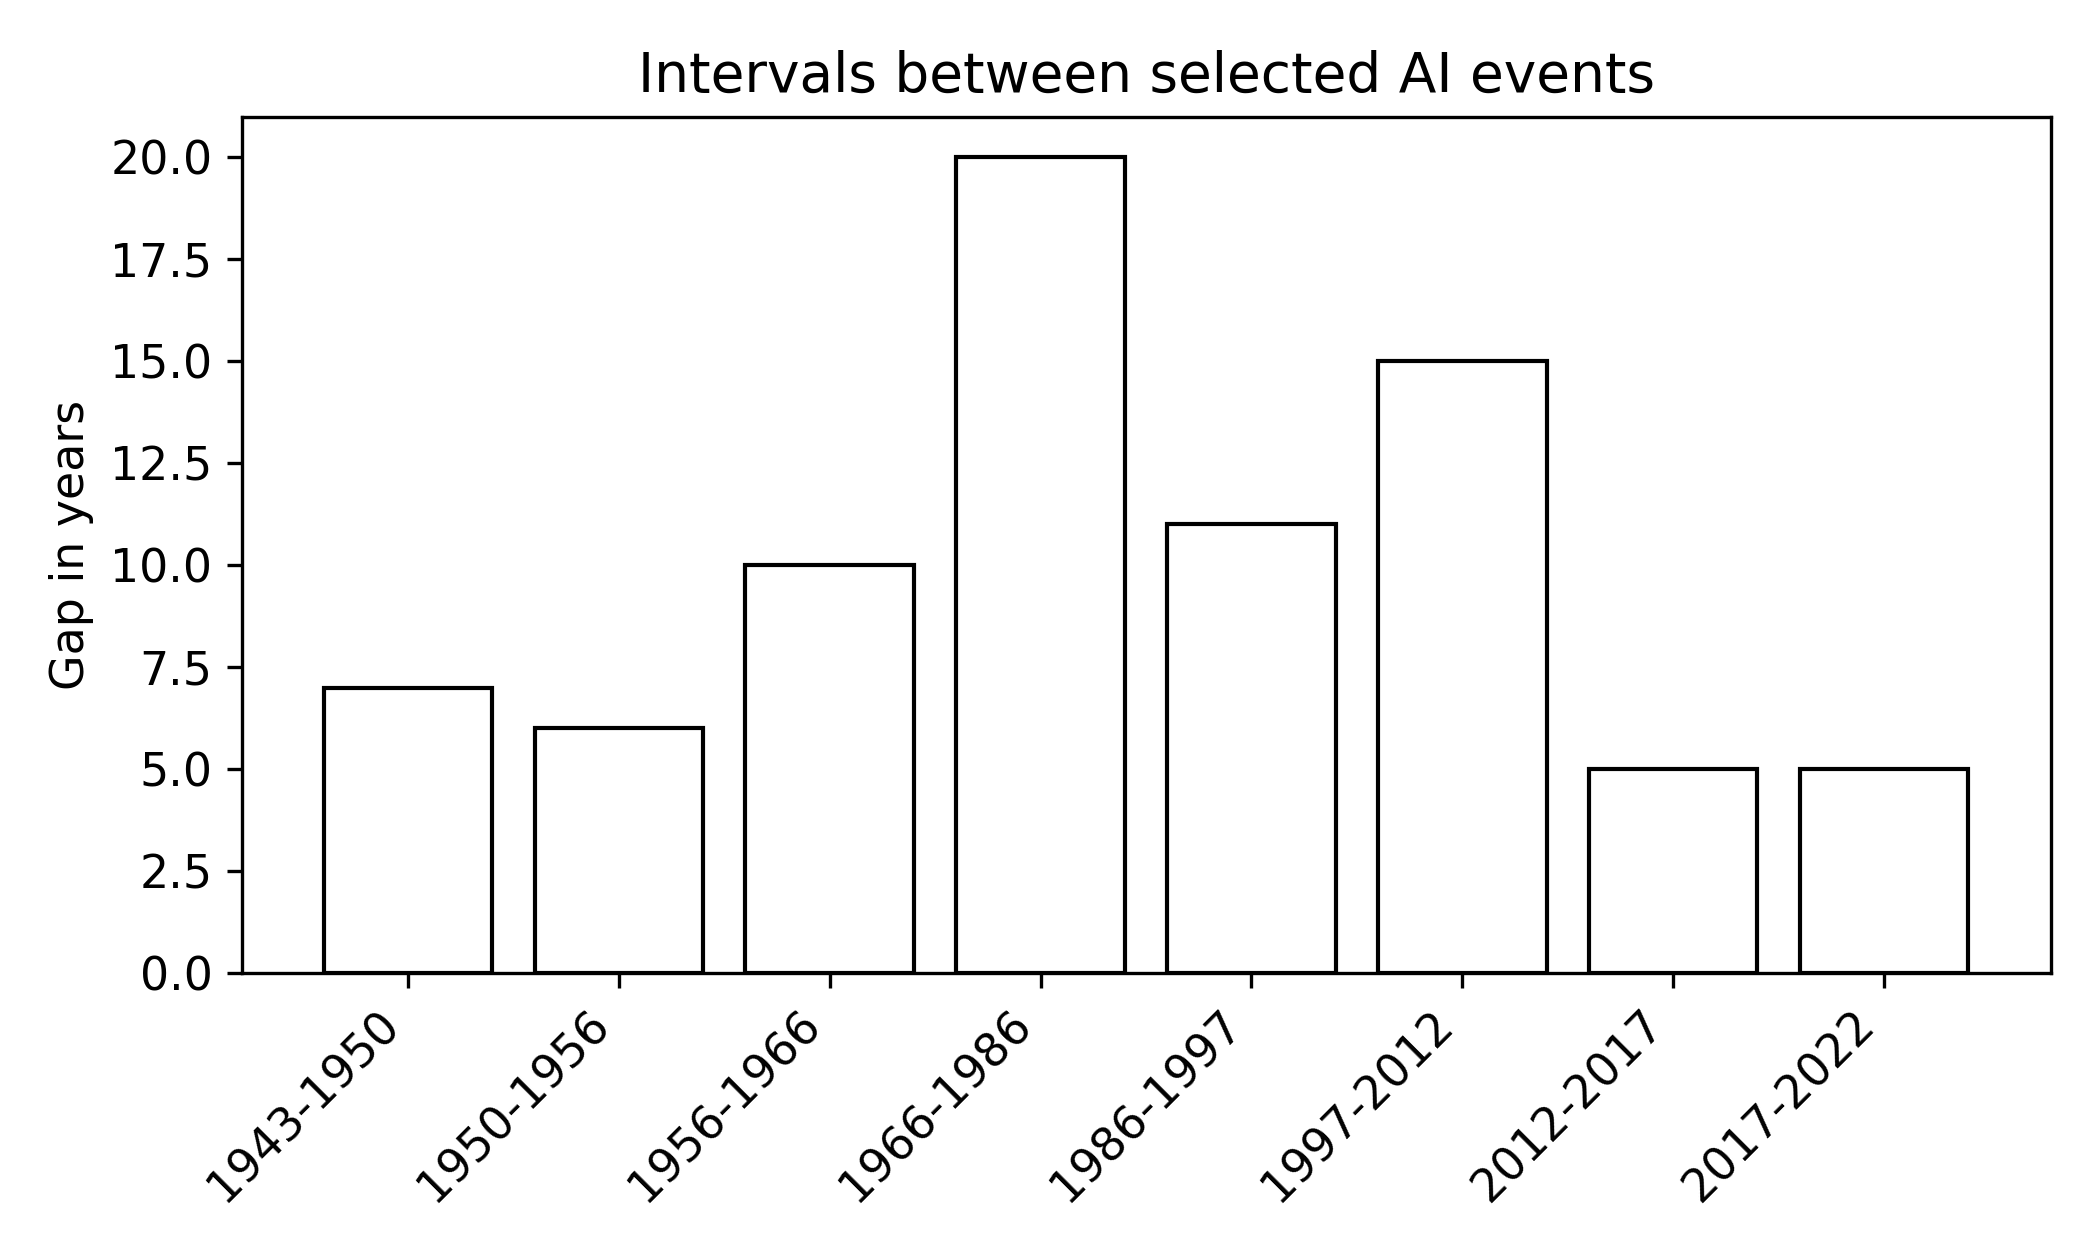

In [6]:
# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Average Gap: {gaps.mean().item():.2f} years")

# 문자 출력(Print)으로 현재 계산 상태를 확인합니다. 화면 반올림 값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Max Gap: {gaps.max().item():.0f} years / Min Gap: {gaps.min().item():.0f} years")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.bar(range(len(gaps)), gaps.cpu().numpy(), facecolor="white", edgecolor="black")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.xticks(range(len(gaps)), [f"{a}-{b}" for a,b in zip(df["연도"][:-1],df["연도"][1:])],rotation=45,ha="right")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.ylabel("Gap in years")

# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.title("Intervals between selected AI events")

# 실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.
figure(OUT,"event_gaps")

# 계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.
report(OUT,"summary",{"events":len(df),"mean_gap":float(gaps.mean()),"seed":SEED,"device":str(device)})

## 그림과 결과 해석

막대 높이는 인접 사건의 연도 차이입니다. 사건 선정이 달라지면 간격도 달라집니다.